In [ ]:
from pathlib import Path
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression;
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from IPython.display import HTML
from matplotlib.animation import FuncAnimation

possiveis_roots = [Path.cwd().resolve(), Path.cwd().resolve().parent]
repo_root = next(
    (caminho for caminho in possiveis_roots if (caminho / "utils.py").is_file()),
    None,
)

if repo_root is None:
    print("Não encontrei 'utils.py'. Isso geralmente significa que o projeto não foi clonado")
    print("ou que o notebook está sendo executado a partir de uma pasta diferente da raiz.")
    print("No Colab, clone o repositório e execute: %cd /content/DataScience-INFOESTE2026")
else:
    sys.path.insert(0, str(repo_root))
    from utils import SingleLinearRegression, MSE, GradientDescent, OLS

In [2]:
from pathlib import Path

possiveis_pastas_dados = [
    Path.cwd() / "datasets",
    Path.cwd() / "aulas" / "datasets",
    Path.cwd().parent / "datasets",
]
PASTA_DADOS = next(
    (caminho for caminho in possiveis_pastas_dados if caminho.is_dir()),
    None,
)

if PASTA_DADOS is None:
    print("Não encontrei a pasta 'datasets'.")
    print("Verifique se o repositório foi clonado por completo e se os datasets existem.")
    print("No Colab, clone o projeto e execute: %cd /content/DataScience-INFOESTE2026")
    print("No VS Code, abra a pasta raiz do projeto antes de executar o notebook.")
    raise FileNotFoundError("Pasta de datasets não encontrada.")


def caminho_dataset(nome_arquivo):
    caminho = PASTA_DADOS / nome_arquivo
    if not caminho.is_file():
        print(f"Não encontrei o arquivo: {caminho}")
        print("O repositório pode não ter sido clonado por completo ou o dataset pode estar ausente.")
        print("Confira a pasta aulas/datasets e, no Colab, confirme que o clone terminou corretamente.")
        raise FileNotFoundError(f"Dataset não encontrado: {caminho}")
    return caminho


print(f"Datasets encontrados em: {PASTA_DADOS.resolve()}")

Datasets encontrados em: /home/dopp/projects/DataScience-INFOESTE2026/aulas/datasets


# Aula 01 - Introdução à Ciência de Dados e IA

Este notebook acompanha os dois blocos da Aula 01. As células preenchidas servem como referência e as células de código incompletas ou vazias serão desenvolvidas ao vivo durante a aula.

## Bloco 1 - Introdução, dados e preparação

Nesta parte, apresentamos Ciência de Dados, o fluxo de um projeto e os fundamentos de preparação e exploração de dados.

## Apresentação

A Ciência de Dados como disciplina teórica requer uma matemática de nível de graduação, principalmente para as disciplinas da Álgebra Linear e Estatística para a manipulação dos dados e dos modelos, e noções de Cálculo para o entendimento de como os modelos 'aprendem' e são treinados. No entanto, neste curso, decidimos simplificar ao máximo as bases matemáticas dos modelos mas sem anular completamente a matemática, tão presente no dia a dia do cientista. Assim, fica implícito, e e muitos casos apenas como referência auxiliar, a matemática mais formal que baseia a área, e espera-se do aluno que deseja seguir na área estude essas áreas, ou siga as dicas recomendadas no material de `proximos-passos.md`.

## O que é Ciência de Dados?

A Ciência de Dados é uma área situada na interseção entre 3 diferentes áreas ou ramos do conhecimento: a Matemática, a Metodologia Científica, e a Programação. De modo geral, o Cientista de Dados se preocupa em trabalhar com dados e informações na finalidade de transformar esses dados em ações cabíveis de serem tomadas, frequentemente envolvendo criação de *modelos preditivos* e *modelos de Inteligência Artificial* pensados em tentar prever o futuro com base no passado.

Ou seja, o Cientista de Dados ajuda na tomada de decisão ao fornecer as ferramentas e as análises necessárias não apenas para *compreender os dados* e *entender o que eles significam* contextualizados, mas também é capaz de *criar algoritmos e métodos que atuam sobre os dados* para prever valores, classificar clientes, estipular riscos, recomendar produtos, entre várias outras. Todas as tarefas abaixo descritas são, por exemplo, cabíveis de serem uma tarefa para um cientista de dados:

- Criar dashboards capazes de traduzir informações do passado e do presente de forma inteligente e dinâmica;
- Costruir um modelo que ajuda a estipular o faturamento da empresa ao longo do tempo;
- Classificar e segmentar clientes entre perfis de risco e de compra, para adotar políticas específicas para cada grupo de cliente;
- Criar um algoritmo capaz de recomendar os melhores produtos dado o perfil do cliente;
- Criar um algoritmo que automaticamente extrair informações de imagens enviadas;
- Computa a potencial mudança nos cliques que uma eventual decisão de design no site podem trazer;

entre outros.

### Analista de Dados ou Cientista de Dados?
Muito se confunde sobre quais são de fato as responsabilidades de um *Cientista de Dados* em constraste com a de um *Analista de Dados*. Esta distinção é ainda mais borrada pelo fato de que muitas empresas não distinguem as duas áreas como separadas. Mas, via de regra, o Cientista de dados é um *Analista de Dados especializado*, com formação mais ampla e adequada para a construção de modelos de aprendizado de máquina e tratamento estatístico mais rigoroso. Além disso, o Cientista de Dados frequentemente está lidando com problemas relacionados *ao futuro*, como planejamento de vendas e previsão de risco, enquanto os analistas de dados costumam focar no passado e presente dos dados.

Existem vários tipos diferentes de aprendizado de máquina e modelos preditivos, muitos dos quais possuem toda uma área de estudo e de especialização apenas para eles. Durante este curso, entretanto, abordaremos principalmente dois tipos de problemas resolvíveis com modelos de aprendizado de máquina: **Regressão* e *Classificação*.
Problemas de *Regressão* estão associados com a previsão de um valor *numérico contínuo*, como por exemplo, prever o preço de um produto a partir de uma série de características. Já problemas de *Classificação* envolvem categorizar os dados em dois ou mais grupos distintos, frequentemente chamados de classes, como criar um modelo que separa clients de alto risco e de baixo risco.

Neste curso, aprendermeos tanto a criar um modelo de regressão, usando *Regressão Linear*, quanto um modelo de classificação, usando *Regressão Logística* na próxima aula.

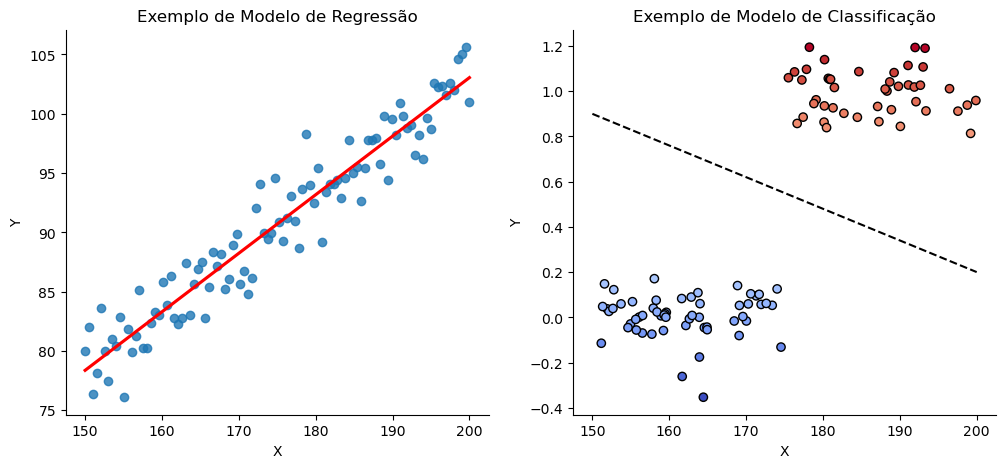

In [2]:
# Exemplo de modelos de ML ilustrativos

# Criar dados de exemplo para regressão linear e SVM
reg_x = np.linspace(150, 200, 100).reshape(-1, 1)
reg_y = 0.5 * reg_x + 3 + np.random.normal(0, 2, size=reg_x.shape)
svm_x = np.random.uniform(150, 200, size=(100, 1))
svm_y = (svm_x > 175).astype(int).ravel() + np.random.normal(0, 0.1, size=svm_x.shape[0])

plt.subplots(1, 2, figsize=(12, 5))

# Gráfico de regressão linear
plt.subplot(1, 2, 1)
sns.regplot(x=reg_x.ravel(), y=reg_y.ravel(), ci=None, line_kws={"color": "red"})
plt.title('Exemplo de Modelo de Regressão')
plt.xlabel('X')
plt.ylabel('Y')
sns.despine()

# Gráfico de SVM
plt.subplot(1, 2, 2)
plt.scatter(svm_x, svm_y, c=svm_y, cmap='coolwarm', edgecolor='k')
sns.lineplot(x=[150, 200], y=[0.9, 0.2], color='black', linestyle='--')
plt.title('Exemplo de Modelo de Classificação')
plt.xlabel('X')
plt.ylabel('Y')
sns.despine()


# Dados e preparação

Dados são registros de observações, eventos ou medidas coletados para responder a uma pergunta. Eles podem estar em tabelas, textos, imagens, séries temporais, áudio ou outras formas. Em uma tabela, cada linha costuma representar uma **observação** e cada coluna, uma **variável**. Antes de analisar, identifique a unidade de observação: uma linha pode representar uma compra, uma pessoa, um sensor em determinado instante ou outro objeto de interesse. Essa definição evita comparar registros que representam coisas diferentes.

As variáveis também têm naturezas distintas. Uma variável **numérica** pode ser discreta, como uma contagem, ou contínua, como uma medida. Uma variável **categórica nominal** identifica grupos sem ordem natural, como região ou tipo de produto; uma categórica **ordinal** tem uma ordem significativa, como níveis de satisfação. Datas, textos e identificadores exigem cuidados próprios. O formato armazenado não define sozinho o significado: códigos como `1`, `2` e `3` podem representar categorias, e um identificador numérico não é necessariamente uma medida.

O contexto dá significado aos valores. Para cada variável, procure saber o que ela representa, sua unidade, como foi medida, quais valores são permitidos, de quando são os dados e qual é sua fonte. Um dicionário de dados com essas informações ajuda outras pessoas a interpretar e reproduzir a análise. A preparação começa pela pergunta que queremos responder e pela verificação de que os dados disponíveis podem ajudar a respondê-la.

## O fluxo ETL

ETL significa **Extract, Transform, Load** (extrair, transformar e carregar). É uma forma de organizar o caminho dos dados desde a fonte até um local preparado para análise:

1. **Extract (extrair):** obter dados de arquivos, planilhas, bancos de dados, sensores, serviços ou outras fontes. É importante registrar a origem e o período coberto.
2. **Transform (transformar):** verificar a estrutura e a qualidade; padronizar formatos e unidades; tratar ausências e duplicatas; combinar fontes quando necessário; e criar representações adequadas à pergunta.
3. **Load (carregar):** armazenar os dados preparados no destino de trabalho, como um banco de dados, um data warehouse ou, neste notebook, um DataFrame do pandas.

Na prática, essas etapas podem ser repetidas e nem sempre acontecem em uma sequência rígida. Em algumas arquiteturas, os dados são carregados antes da transformação (ELT). Ao ler um CSV com o pandas, por exemplo, obtemos os dados de uma fonte e os carregamos em memória; depois podemos verificar e transformar as colunas. Preserve a fonte original quando possível e documente as mudanças para que a análise possa ser refeita e auditada.

In [4]:
df = pd.read_csv(caminho_dataset("FuelConsumptionCo2.csv"))
df.head()

,MODELYEAR,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,CYLINDERS,TRANSMISSION,FUELTYPE,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
0,2014,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,2014,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,2014,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,2014,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,2014,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067 entries, 0 to 1066
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   MODELYEAR                 1067 non-null   int64  
 1   MAKE                      1067 non-null   object 
 2   MODEL                     1067 non-null   object 
 3   VEHICLECLASS              1067 non-null   object 
 4   ENGINESIZE                1067 non-null   float64
 5   CYLINDERS                 1067 non-null   int64  
 6   TRANSMISSION              1067 non-null   object 
 7   FUELTYPE                  1067 non-null   object 
 8   FUELCONSUMPTION_CITY      1067 non-null   float64
 9   FUELCONSUMPTION_HWY       1067 non-null   float64
 10  FUELCONSUMPTION_COMB      1067 non-null   float64
 11  FUELCONSUMPTION_COMB_MPG  1067 non-null   int64  
 12  CO2EMISSIONS              1067 non-null   int64  
dtypes: float64(4), int64(4), object(5)
memory usage: 108.5+ KB


### Verificação e limpeza dos dados

Antes de corrigir ou remover valores, faça um **perfil inicial** do conjunto: confira dimensões, nomes e tipos de colunas, exemplos de registros, valores distintos, duplicatas, intervalos e quantidade de ausências. Em pandas, `df.shape`, `df.head()`, `df.info()`, `df.isna().sum()` e `df.nunique()` ajudam nessa inspeção. A limpeza deve responder a problemas identificados, e não aplicar regras automaticamente só porque estão disponíveis.

A qualidade dos dados envolve mais do que a ausência de valores. Verifique se os registros são completos, se os valores respeitam regras válidas, se unidades e categorias estão consistentes e se chaves que deveriam identificar registros são únicas. Por exemplo, datas fora do período esperado, medidas em unidades misturadas e categorias escritas de formas diferentes podem distorcer uma análise mesmo sem produzir erros de execução.

Valores ausentes podem aparecer como `NaN`, `None` ou `NaT`. `isna()` ajuda a localizá-los; `fillna()` substitui valores e `dropna()` remove linhas ou colunas. A decisão depende da quantidade e do padrão das ausências, da variável e da pergunta. Preencher uma medida pela média pode reduzir variação e ser inadequado para uma distribuição assimétrica; preencher com zero só faz sentido quando zero representa de fato o significado correto. Remover registros também pode introduzir viés se as ausências ocorrerem mais em certos grupos. Em alguns casos, vale manter uma indicação de que o valor estava ausente.

Confira os tipos e formatos. Texto que deveria ser numérico pode conter espaços, separadores decimais ou símbolos; `pd.to_numeric()` converte valores compatíveis, e `errors='coerce'` transforma os incompatíveis em ausências que precisam ser investigadas. Para datas, `pd.to_datetime()` pode ajudar. Padronize categorias e unidades antes de compará-las. Lembre-se de que uma categoria nominal não se torna uma medida apenas por receber um número: a codificação deve respeitar o tipo de variável e o método de análise.

Valores extremos não são necessariamente erros, e duplicatas podem ser registros repetidos ou observações legítimas. Investigue o contexto antes de removê-los. Em tarefas de aprendizado de máquina, divida os dados em treino e avaliação antes de estimar regras como imputação, escalonamento ou codificação; ajuste essas regras no treino e aplique-as às demais partes para evitar **vazamento de dados**. Preserve os dados brutos e registre as decisões de limpeza.

In [5]:
#Tratamento de dados nulos
SeriesNulos = pd.Series([np.nan, 13, 15, np.nan, 25, 30, 35, 40, np.nan, 50])
print(SeriesNulos)

0     NaN
1    13.0
2    15.0
3     NaN
4    25.0
5    30.0
6    35.0
7    40.0
8     NaN
9    50.0
dtype: float64


In [ ]:
#Tratamento de tipos inconsistentes

SeriesNums = pd.Series(['1.0', '2.0', '3.0', '4.0', '5.0', '6.0', '7.0', '8.0', '9.0', '10.0'])
SeriesMoney = pd.Series(['R$12,00', 'R$5,50', 'R$83,99', 'R$2,00', 'R$120,00', 'R$8,00', 'R$1,00', 'R$15,00'])
print(SeriesNulos)
print(SeriesMoney)

0     12.00
1      5.50
2     83.99
3      2.00
4    120.00
5      8.00
6      1.00
7     15.00
dtype: float64


## Análise Exploratória de Dados (EDA)

**EDA** vem de *Exploratory Data Analysis*, ou análise exploratória de dados. É o processo de examinar um conjunto para entender sua estrutura, suas distribuições e suas limitações antes de formular conclusões ou treinar modelos. A EDA combina perguntas, resumos numéricos e visualizações; não é apenas a produção de gráficos.

Comece por uma variável de cada vez: observe tipo, valores possíveis, ausências, frequências e distribuição. Depois compare variáveis ou grupos. A escolha da análise depende dos tipos envolvidos: tabelas de frequência ajudam com categorias; histogramas e boxplots resumem variáveis numéricas; tabelas e gráficos comparativos podem revelar diferenças entre grupos ou associações entre medidas. Em conjuntos maiores, também é útil investigar padrões em várias variáveis e verificar se os resultados mudam entre períodos ou subgrupos.

A exploração pode revelar erros de coleta, categorias raras, desequilíbrios, relações inesperadas e perguntas que merecem investigação. Registre o que observou e quais decisões tomou. Um padrão visual é uma pista, não uma prova: ele pode depender da amostra, de escolhas de escala ou de dados ausentes. Interprete-o à luz de como os registros foram coletados e do que cada variável realmente significa. EDA ajuda a gerar hipóteses; confirmar explicações e relações causais exige métodos e evidências adicionais.

### Estatísticas descritivas

Estatísticas descritivas condensam muitos registros em medidas que ajudam a compreender uma variável. Em pandas, `df.describe()` resume por padrão as colunas numéricas e ignora valores ausentes ao calcular cada medida. Entre os resultados estão:

- **count:** número de valores não ausentes usados no resumo. Compare-o ao total de registros para perceber possíveis lacunas.
- **mean (média):** soma dos valores dividida pela quantidade. Usa todas as observações e pode ser bastante afetada por valores extremos.
- **std (desvio padrão):** resume o quanto os valores tendem a se afastar da média; sua interpretação depende da escala da variável e da forma da distribuição.
- **min e max:** extremos observados. Eles mostram o intervalo da amostra, mas não dizem sozinhos se os valores são típicos ou válidos.
- **25%, 50% e 75%:** quartis. A mediana (50%) divide os valores ordenados em duas metades; os quartis descrevem partes da distribuição sem depender tanto dos extremos quanto a média.

Leia as medidas em conjunto e considere também a pergunta, a escala e o tamanho da amostra. Média distante da mediana pode indicar assimetria ou valores extremos, mas é um motivo para investigar, não uma conclusão automática. Duas variáveis podem ter a mesma média e dispersão e ainda apresentar distribuições muito diferentes; por isso, estatísticas devem ser combinadas com gráficos e conhecimento do contexto.

Para incluir colunas categóricas, use `df.describe(include='all')`. O pandas apresenta resumos apropriados a esses tipos, como quantidade de valores, quantidade de categorias distintas, categoria mais frequente e sua frequência. Para perguntas específicas, `value_counts()` também permite examinar a frequência de cada categoria.

In [7]:
#Estatísticas descritivas com describe

### Histograma

Um histograma mostra como os valores de uma variável numérica se distribuem. Ele divide a escala em **intervalos** (ou *bins*) e conta quantas observações caem em cada um. O eixo horizontal representa os intervalos; a altura das barras representa a frequência ou, quando normalizada, a densidade. As barras costumam encostar porque os intervalos correspondem a trechos contíguos de uma escala numérica.

Observe onde os dados se concentram, quanto se espalham, se a distribuição parece simétrica ou assimétrica, se há mais de um agrupamento e se aparecem lacunas ou valores isolados. Esses padrões podem orientar perguntas, mas não identificam por si só a causa. A forma também depende da largura e da posição dos intervalos: bins muito largos escondem detalhes; bins muito estreitos podem destacar variações aleatórias. Ao comparar grupos, use escalas e intervalos compatíveis.

A opção `kde=True` acrescenta uma curva suave que estima a densidade da distribuição. Ela resume uma forma possível dos dados, mas não liga as observações nem representa uma contagem exata. A curva depende de escolhas de suavização e deve ser lida como apoio ao histograma, não como substituto dele.

In [8]:
#Histograma com CO2EMISSIONS

### Boxplot e possíveis outliers

Um boxplot resume uma variável numérica por meio de quartis. **Q1** é o primeiro quartil, **Q2** é a mediana e **Q3** é o terceiro quartil. A caixa vai de Q1 a Q3 e contém os 50% centrais das observações; a linha interna marca a mediana. A distância entre Q3 e Q1 é o **intervalo interquartil**: `IQR = Q3 − Q1`. Uma caixa ou um intervalo entre os bigodes maior indica mais dispersão na escala representada.

Na convenção comum de Tukey, os limites são `Q1 − 1,5 × IQR` e `Q3 + 1,5 × IQR`. Os bigodes vão até os valores observados mais distantes que ainda ficam dentro desses limites; valores além deles aparecem como pontos separados e são sinalizados como **possíveis outliers**. Eles não são necessariamente o mínimo e o máximo. Ferramentas podem usar outras convenções, então confira a configuração do gráfico antes de interpretá-lo.

Um ponto sinalizado merece investigação, não remoção automática. Pode ser erro de registro, evento raro válido, diferença entre subgrupos ou indício de que outra escala ou representação é mais adequada. O boxplot facilita comparar a mediana e a dispersão de grupos, mas oculta a forma detalhada da distribuição e não mostra bem quantas observações há em cada grupo; complemente-o com contagens, histogramas ou outros gráficos quando necessário. As caixas exibidas na célula seguinte são um exemplo de comparação entre categorias do conjunto usado na aula.

In [9]:
#Boxplot com CO2EMISSION e FUELTYPE

### Correlação entre variáveis

Uma matriz de correlação resume a associação entre pares de variáveis numéricas. O método padrão de `df.corr()` no pandas é a correlação de **Pearson**, que varia de **−1 a 1**: valores positivos indicam que as variáveis tendem a aumentar juntas em uma relação linear; valores negativos indicam que uma tende a diminuir quando a outra aumenta; valores próximos de zero indicam pouca associação **linear** observada.

O mapa de calor codifica esses valores por cor para facilitar comparações entre pares. Observe o sinal e a intensidade, mas também confira os números, a quantidade de observações e o contexto. A correlação de Pearson pode ser sensível a valores extremos e não descreve bem relações curvas. Um valor próximo de zero não descarta uma relação não linear.

Correlação não demonstra causalidade. Uma associação pode surgir por acaso, por uma terceira variável relacionada a ambas ou por seleção dos registros. Além disso, se uma categoria nominal for codificada como `0`, `1`, `2`, essa numeração pode criar uma ordem artificial; uma correlação calculada sobre esses códigos pode não ter interpretação útil. Use a matriz como ferramenta de exploração e verifique as relações com conhecimento do problema e análises apropriadas.

In [10]:
#heatmap

# Feature Engineering

**Feature engineering** (engenharia de atributos) é o processo de criar, transformar ou selecionar variáveis para representar melhor um problema de análise ou aprendizado de máquina. Uma *feature* (atributo) é uma informação usada como entrada de uma análise ou modelo. Boas features traduzem conhecimento sobre o problema em uma representação que o método consegue utilizar; elas não substituem a verificação da qualidade dos dados nem garantem, sozinhas, um bom modelo.

As operações dependem da pergunta e dos dados. Podemos transformar uma escala, combinar medidas relacionadas, extrair ano ou mês de uma data, resumir eventos por pessoa ou período, contar termos em textos, tratar valores categóricos ou selecionar variáveis relevantes. Antes de criar uma feature, pergunte o que ela significa, em que unidade está, se estará disponível no momento em que uma previsão for feita e se a transformação pode ser explicada e reproduzida.

A representação de categorias exige atenção. Atribuir números a categorias **nominais** pode dar a impressão falsa de que existe uma ordem ou distância entre elas. Para muitos modelos, uma codificação *one-hot* é mais apropriada; para categorias ordinais, uma codificação ordenada só faz sentido quando a ordem tem significado. A técnica também depende do modelo utilizado.

Evite **vazamento de dados**: uma feature não deve usar informação que só será conhecida depois do evento que se quer prever nem o próprio resultado que o modelo deveria estimar. Em tarefas preditivas, regras aprendidas dos dados — como escalas, imputações e seleções — devem ser ajustadas apenas nos dados de treino e depois aplicadas à validação ou ao teste. Compare novas features com uma referência simples e avalie o resultado em dados separados.

As próximas células ilustram algumas transformações com as colunas do conjunto usado nesta aula. Os códigos de categoria e as faixas de classificação são exemplos didáticos, não regras universais: em outro problema, unidades, categorias, limites e justificativas podem ser diferentes e precisam ser definidos e documentados com base no contexto.

In [11]:
# Criar coluna de classificação de consumo com base nas medidas de consumo

## Bloco 2 - Regressão Linear e aprendizado do modelo

A partir daqui, estudamos linearidade, função de custo, derivada, gradiente descendente e construímos uma regressão linear do zero.

In [5]:
df = pd.read_csv(caminho_dataset("NHANES-2017-2018-height-weight.csv"))
df.drop(columns=["Unnamed: 0"], inplace=True)

# O que é linearidade?
Para estudarmos os próximos modelos, é fundamental conhecermos o conceito de linearidade. Esse é um conceito estudado na disciplina de álgebra linear que não será aprofundada neste curso, mas, podemos ter um princípio de uma noção mais intuitiva analisando um exemplo em específico no gráfico abaixo. Observe que o gráfico não tem título e nem eixo Y: isso é *proposital*, pois esse gráfico na verdade é um *recorte* de um gráfico maior. Logo entenderemos por que fizemos esse corte.

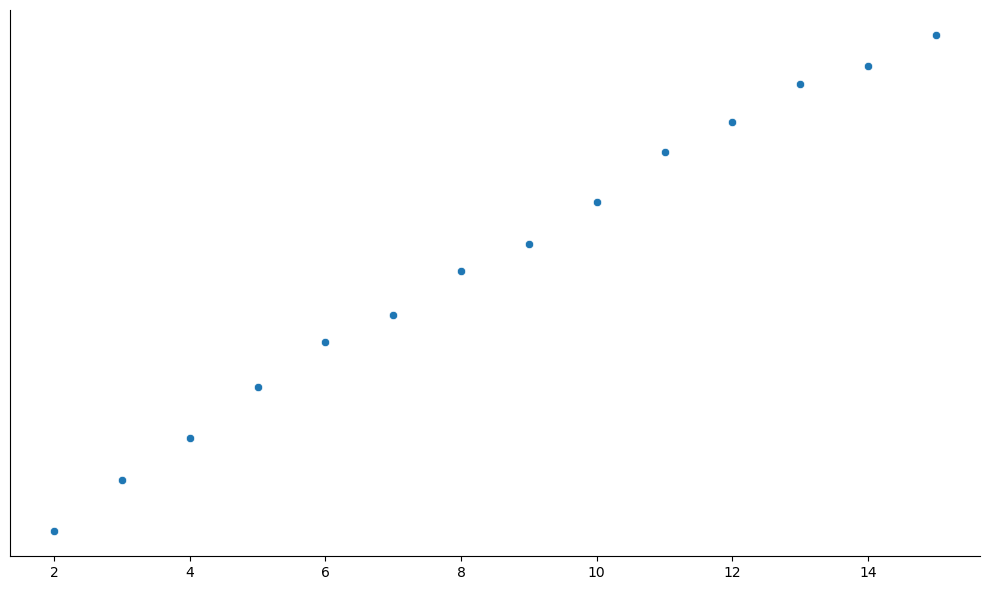

In [13]:
# Criar dados medianos
mediana_altura = df.groupby('age')['height'].median()

# Gráfico da mediana de altura apenas com X <= 15

plt.figure(figsize=(10, 6))
sns.scatterplot(x=mediana_altura[mediana_altura.index <= 15].index, y=mediana_altura[mediana_altura.index <= 15].values, marker='o')

# Esconder nome do titulo e dos eixos x e y
plt.title('')
plt.xlabel('')
plt.ylabel('')

# Esconder labels dos eixos
plt.yticks([])

sns.despine()
plt.tight_layout()
plt.show()

Pelo menos para o período cortado do gráfico (cortado até $x = 15$), que não necessariamente representa toda a distribuição, parece claro deduzir que esta distribuição pode ser representada por uma *linha reta* ou *relação linear* entre os dados, já que claramente existe uma tendência de que, a medida em que se aumenta o x, aumenta-se o y. Podemos associar a esta relação uma *reta* que relaciona valores de X para respectivos valores de Y.

Os detalhes em como essa reta pode ser criada ficarão para os próximos tópicos: por enquanto, vamos apenas considerar que nós traçamos uma reta quaisquer representando esse crescimento linear nos dados em Y com relação ao X.

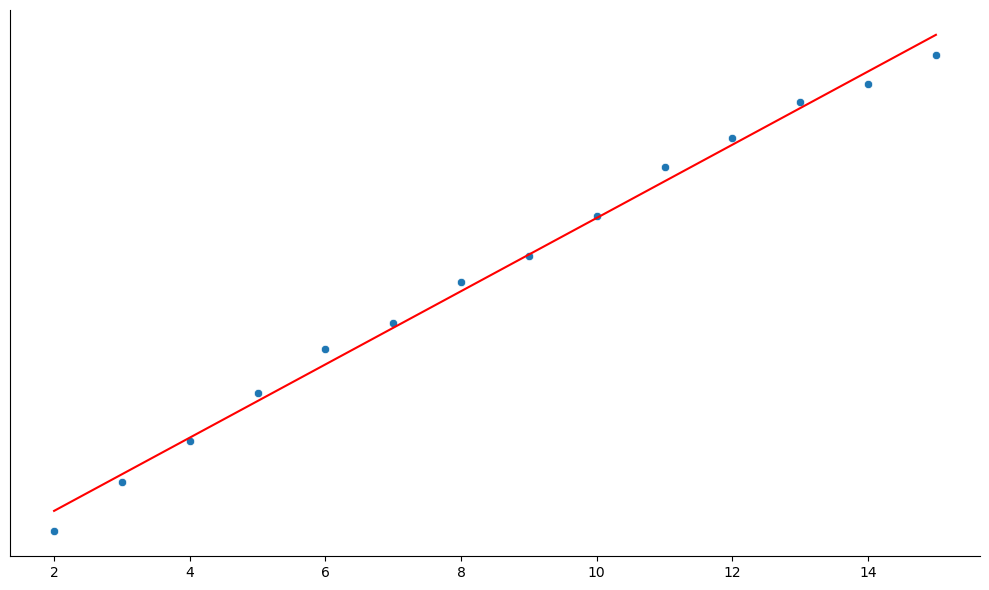

In [14]:
# Criar uma regressão linear ols APENAS para os dados X <= 15 e plotar a reta

x = mediana_altura[mediana_altura.index <= 15].index.values.reshape(-1, 1) # reshape para transformar em array 2D
y = mediana_altura[mediana_altura.index <= 15].values.reshape(-1, 1)

model = SingleLinearRegression()
ols = OLS()
model = ols.fit(model, x, y)
y_pred = model.predict(x)

# Plotar a reta
plt.figure(figsize=(10, 6))
sns.scatterplot(x=x.flatten(), y=y.flatten(), marker='o')
plt.plot(x, y_pred, color='red')

# Esconder nome do titulo e dos eixos x e y
plt.title('')
plt.xlabel('')
plt.ylabel('')

# Esconder labels dos eixos
plt.yticks([])

sns.despine()
plt.tight_layout()
plt.show()

Perceba que, agora que nós determinamos explicitamente uma *relação linear* entre Y em X, nós poderíamos usar de um artifício de "extrapolar a reta": ver quais valores de Y obteríamos a medida que os valores de X aumentam ainda mais acima de 15, como se estivéssemos projetando a reta para frente. Deixando os detalhes de como essa reta foi criada de lado momentamente, podemos observar algo interessante quando avaliamos o valor de y quando $x = 80$:

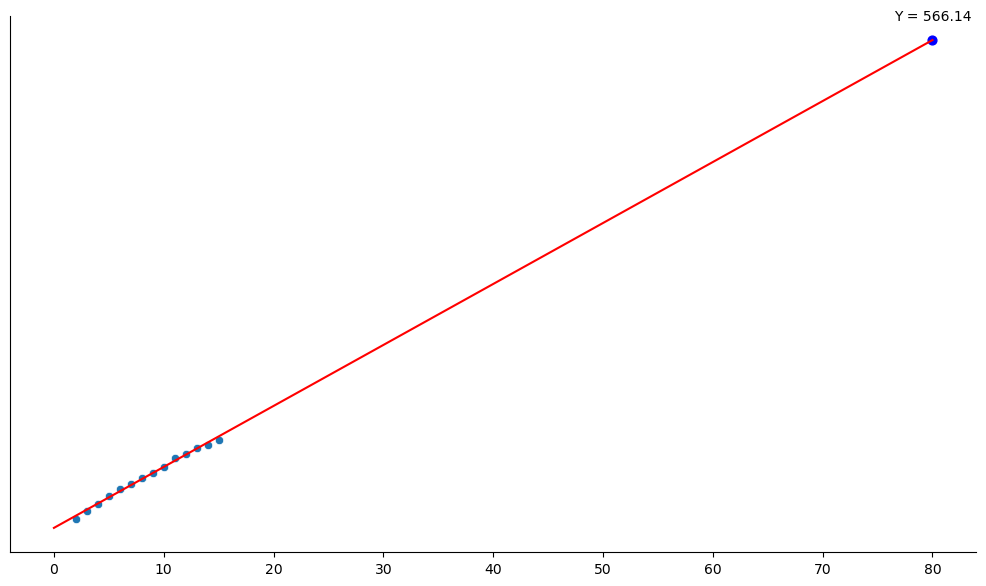

In [15]:
# Plotar gráfico extrapolado até o X = 80, usando a reta da regressão OLS treinada apenas com os dados X <= 15

x_estrapolado = np.arange(0, 81).reshape(-1, 1)
y_estrapolado = model.predict(x_estrapolado)
y_80 = model.predict(np.array([[80]]))
y_80_valor = y_80.item()

# Plotar a reta extrapolada
plt.figure(figsize=(10, 6))
sns.scatterplot(x=x.flatten(), y=y.flatten(), marker="o")
plt.plot(x_estrapolado.flatten(), y_estrapolado.flatten(), color="red")

# Exibir o ponto X = 80
plt.scatter(80, y_80_valor, color="blue", s=40, label=f"Y(80) = {y_80_valor:.2f}")

# Texto acima do ponto
plt.annotate(f"Y = {y_80_valor:.2f}", xy=(80, y_80_valor), xytext=(0, 12), textcoords="offset points", ha="center", va="bottom")

plt.title("")
plt.xlabel("")
plt.ylabel("")
plt.yticks([])
sns.despine()
plt.tight_layout()
plt.show()

Ou seja, quando extrapolamos a reta e a utilizamos para prever valores *maiores* que $x = 15$, mesmo que ainda não estejamos exibindo os dados de Y para esses valores de X (lembre-se, o gráfico está com uma quantidade de dados específica, uma parte da distribuição total, por motivos que já serão esclarecidos), nós conseguimos *prever* ou *inferir* valores de Y correspondentes. Isso voltará a ser pertinente no próximo tópico sobre Regressão Linear, onde aprenderemos não apenas o que de fato essa reta representa, mas também como criar a melhor reta possível.

Mas primeiro, lembrando que o dataset não contém o conjunto completo dos dados, vamos revelar os verdadeiros nomes dos eixos nas distribuições originais e vermos se nossa interpretação inicial faz algum sentido.

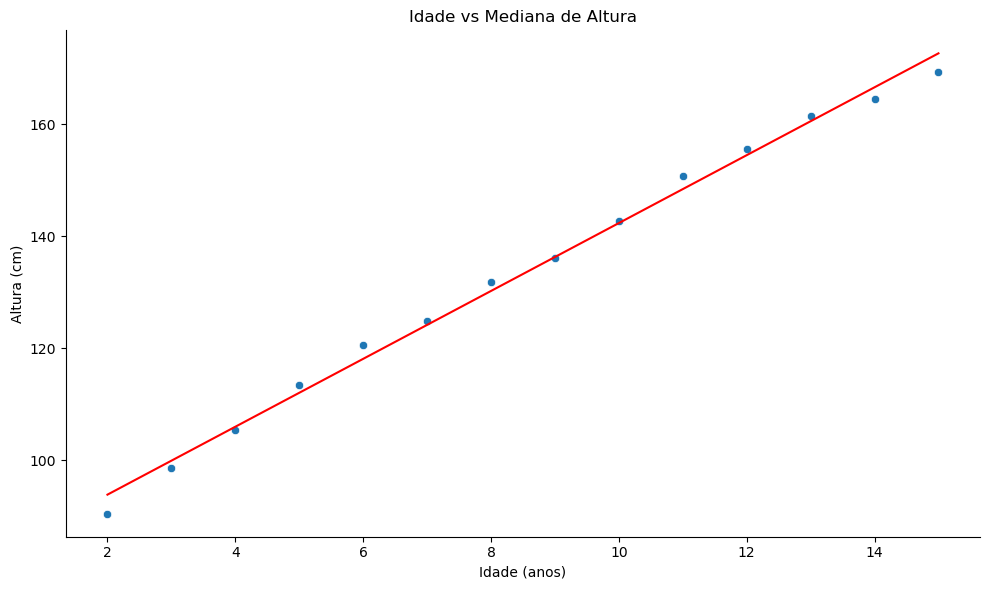

In [16]:
# Mesmo gráfico, mas com nome nos eixos

# Plotar a reta
plt.figure(figsize=(10, 6))
sns.scatterplot(x=x.flatten(), y=y.flatten(), marker='o')
plt.plot(x, y_pred, color='red')

# Esconder nome do titulo e dos eixos x e y
plt.title('Idade vs Mediana de Altura')
plt.xlabel('Idade (anos)')
plt.ylabel('Altura (cm)')

sns.despine()
plt.tight_layout()
plt.show()

Agora com os eixos revelados, faz sentido ainda pensar que a relação entre idade e altura é linear? Isto é, faz sentido a ideia de que, a medida em que a idade aumenta, aumenta-se cada vez mais a altura?
Isso parece longe da verdade. De fato, ao exibirmos a verdadeira distribuição dos dados em comparação com a reta que criamos:

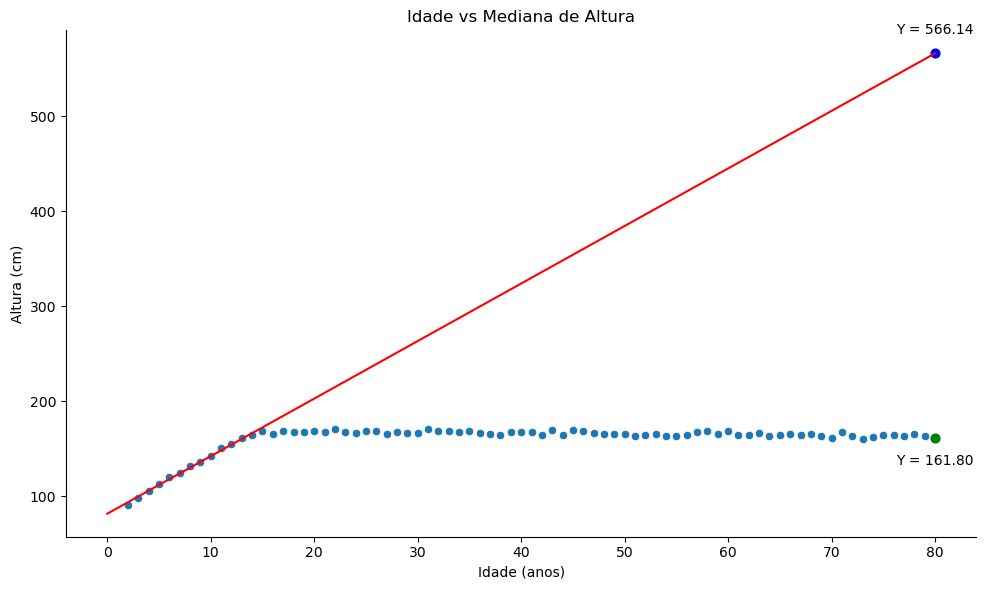

In [17]:
# Gráfico completo com a reta prevista para X <= 15.
y_80 = mediana_altura[mediana_altura.index == 80].item()

plt.figure(figsize=(10, 6))
sns.scatterplot(x=mediana_altura.index, y=mediana_altura.values, marker='o')
sns.lineplot(x=x_estrapolado.flatten(), y=y_estrapolado.flatten(), color='red')
plt.scatter(80, y_80_valor, color="blue", s=40, label=f"Y(80) = {y_80_valor:.2f}")
plt.annotate(f"Y = {y_80_valor:.2f}", xy=(80, y_80_valor), xytext=(0, 12), textcoords="offset points", ha="center", va="bottom")
plt.scatter(80, y_80, color="green", s=40, label=f"Y(80) = {y_80:.2f}")
plt.annotate(f"Y = {y_80:.2f}", xy=(80, y_80), xytext=(0, -12), textcoords="offset points", ha="center", va="top")

plt.xlabel('Idade (anos)')
plt.ylabel('Altura (cm)')

sns.despine()
plt.title('Idade vs Mediana de Altura')
plt.tight_layout()
plt.show()

Podemos ver que nossa previsão errou significantemente quando consideramos apenas o conjunto inicial dos dados, atribuindo um valor de Y = 566, ou *5 metros de altura*, para pessoas com idade próxima a 80. Isto obviamente não pode ser correto, e o gráfico mostra um claro padrão na mediana das idades a partir de X = 15-18, onde as pessoas **param de crescer** e portanto, a relação linear que surge nos primeiros pontos de y em relação a X não se mantém válida para os demais pontos de X. 

Este é um bom exemplo de uma relação **não-linear**, isto é, a relação entre X (idade) e Y (altura) não pôde ser facilmente expressão por meio de uma relação linear entre suas variáveis. A relação até pode ser descrita como linear até valores próximos de $x = 18$, quando rapidamente a taxa de crescimento diminui e se estabiliza, tornando a distribuição inteira um exemplo de uma distribuição não linear.

 Descobrir primeiro um exemplo de uma relação não-linear pode ser útil para entender os limites do que modelos de aprendizado de máquina lineares, como o que veremos em seguida, podem possuir. 

# Regressão Linear
A Regressão Linear é um modelo de Aprendizado de Máquina, e portanto, se propõe a *prever* valores de Y de saída com base em valores X de entrada, por meio de uma *função linear* entre as variáveis. Intuitivamente, o modelo de Regressão Linear pode ser entendido como uma tentativa de *encaixar uma reta que melhor representa o conjunto dos dados*. Essa noção intuitiva, porém, pode ser incompleta em casos onde há mais de uma variável de entrada (isto é , mais de um "x"). Para fins deste curso, focaremos no entendimento na **Single Linear Regression**, ou Regressão Linear Singular, com apenas uma variável de entrada e uma variável de saída, mas um estudo mais aprofundado na álgebra linear dará as ferramentas necessárias para entender a regressão múltipla.

No Ensino Médio, aprende-se que uma reta pode ser representada no plano da seguinte forma:

$$\boxed{y = ax +b}$$

com $a$ sendo chamado de *coeficiente angular*, responsável pela inclinação da reta,  
e *b* sendo chamado de intercepto, onde a reta cruza com o eixo y.  

Experimente substituir os valores de $a$ e de $b$ no código abaixo para ver a mudança no gráfico.

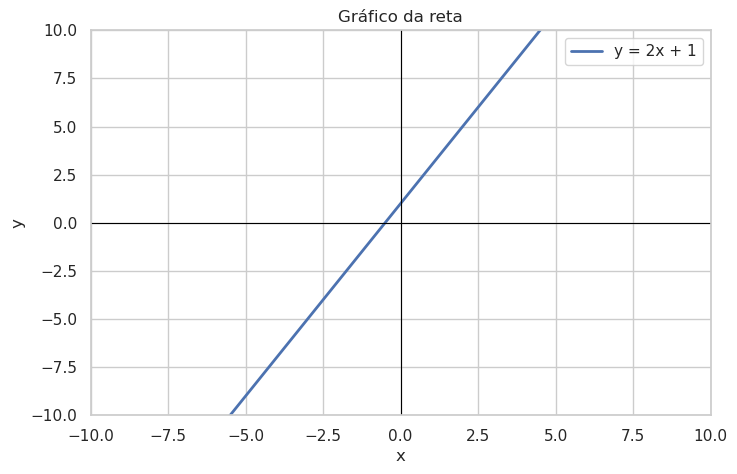

In [18]:
a = 2   # Coeficiente angular (inclinação)
b = 1   # Intercepto (onde a reta cruza o eixo y)

x = np.linspace(-10, 10, 200)
y = a * x + b

sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))
plt.plot(x, y, label=f"y = {a}x + {b}", linewidth=2)

plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(0, color="black", linewidth=0.8)

# Limites fixos dos eixos
plt.xlim(-10, 10)
plt.ylim(-10, 10)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Gráfico da reta")
plt.legend()
plt.show()

Assim sendo, se temos uma distribuição com valores de X e de Y, e queremos criar uma reta que melhor os represente, podemos modelar isso como:

$\hat{y} = ax + b$, onde $\hat{y}$ representa o valor previsto por nosso modelo (o que nosso modelo devolve para *aquela* entrada específica de x).  
Se *x* representa os valores que nós temos como "entrada" e $\hat{y}$ o valor previsto pelo modelo, isso significa que os únicos parâmetros que podemos 'mexer' são as variáveis $a$ e $b$. Ou seja, queremos encontrar quais $a$ e $b$ são os mais *eficazes* para representar os dados.

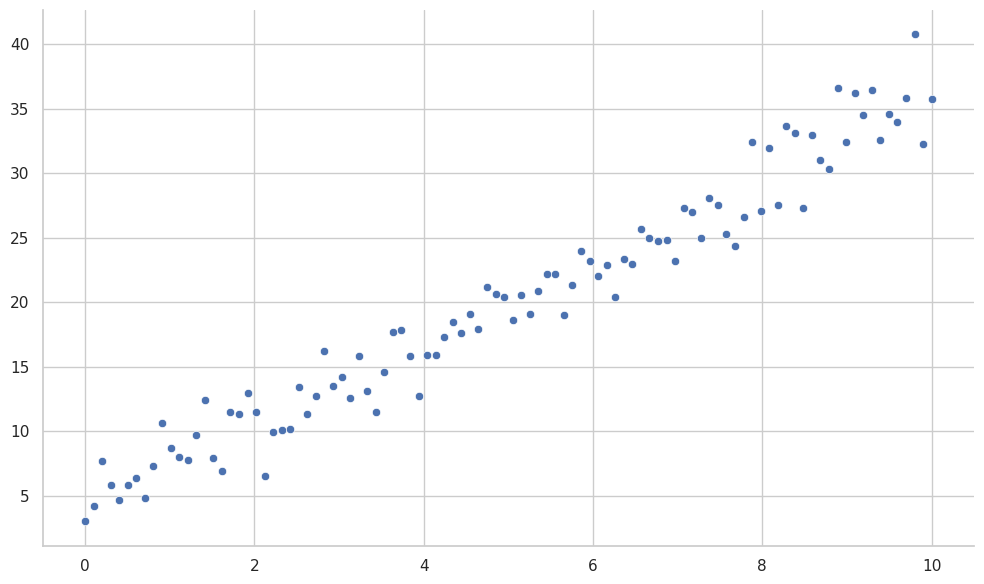

In [19]:
# Gerar dados lineares com ruído gaussiano para representar uma certa relação linear arbitrária

x = np.linspace(0, 10, 100)
y = 3 * x + 5 + np.random.normal(0, 2, size=x.shape)  # y = 3x + 5 + ruído gaussiano

plt.figure(figsize=(10, 6))
sns.scatterplot(x=x, y=y, marker='o')
sns.despine()
plt.tight_layout()
plt.show()

Para definirmos o que significa realmente uma "melhor" reta, precisamos de um *parâmetro*, que nos permita diferenciar diferentes possíveis retas. 

## Apresentando a Função de Custo - Erro Médio Quadrático

O que significa, matematicamente, "melhor"? Para que um computador possa buscar a *melhor* reta, precisamos transformar essa ideia intuitiva em um **número**, que nos diga quão boa (ou quão ruim) é uma determinada reta. Para isso, utilizamos uma **Função de Custo**.
Intuitivamente, uma Função de Custo é uma função matemática que irá *quantificar o erro do modelo*, isto é, vai dizer o quão mal o modelo performa se comparado com a verdadeira natureza da distribuição. Com essa função de custo em mãos, podemos montar um algoritmo ou procedimento que tenta ao máximo *ajustar o modelo para minimizar os erros*, até chegar em um ponto onde o modelo está satisfatório.

Existem diferentes funções de custo, com diferentes motivações por trás. Algumas são melhores para certos tipos de modelo, e outras possuem interpretações diferentes que podem se adequar melhor em casos específicos. Contudo, de longe o modelo mais utilizado é o **Erro Médio Quadrático**, ou **MSE (Mean Squared Error)**. Ele possui a seguinte fórmula.

$$\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2$$

$n$ : número de features (linhas)  
$\sum_{i=1}^{n}$ : soma do i-ésimo elemento = 1 até n  
$\hat{y}$ : predição do modelo


A notação pode assustar, mas é realmente mais simples do que parece. O Erro Médio Quadrático estará medindo **o quanto o modelo erra, em média**. Perceba primeiro o termo $(y_i - \hat{y})$: essa é simplesmente a diferença entre o valor que o **modelo preveu** do valor real dos dados, isto é, representa o **erro** do nosso modelo, por se assim dizer.  
Nós **elevamos esse erro ao quadrado**, depois **somamos todos os erros quadráticos**, e **dividimos pela quantidade de linhas**, obtendo por fima uma **média dos erros quadráticos**.

### Por que elevar ao quadrado?
Uma questão válida que pode ter surgido é por que, ao pegarmos a diferença entre o valor previsto pelo modelo e o valor real do modelo, nós elevamos esse erro ao quadrado. Na verdade, isso é feito por 3 motivos principais:

1. **Manter os valores positivos**: todo número real elevado ao quadrado se transforma em número positivo. Isso é relevante para nós, pois sem essa transformação, teríamos **erros positivos** e **erros negativos** se cancelando. Por exemplo, se para um certo X nosso modelo errou em *-10* (errou -10 unidades, errou 'pra baixo'), e pra um outro X errou *+10* (errou 10 unidades, errou 'pra cima'), esses dois erros de cancelariam na soma e pareceria que o modelo não errou nada para esses dois X, quando na verdade, o modelo errou duas 20 unidades no total.
2. **Penaliza erros altos**: a função quadrática é não-linear e fazer com que números grandes ficam significantemente maiores ao se elevarem ao quadrado do que ficariam em uma simples relação linear, fazendo com que erros mais graves sejam penalizados em relação a uma reta com potencialmente erros menos graves em magnitude.
3. **Suaviza a função de erro**: Um conceito mais avançado de Cálculo, mas elevar ao quadrado torna a função de custo significantemente mais fácil de ser calculada por algoritmos devido a ser uma função derivável em todo o ponto.

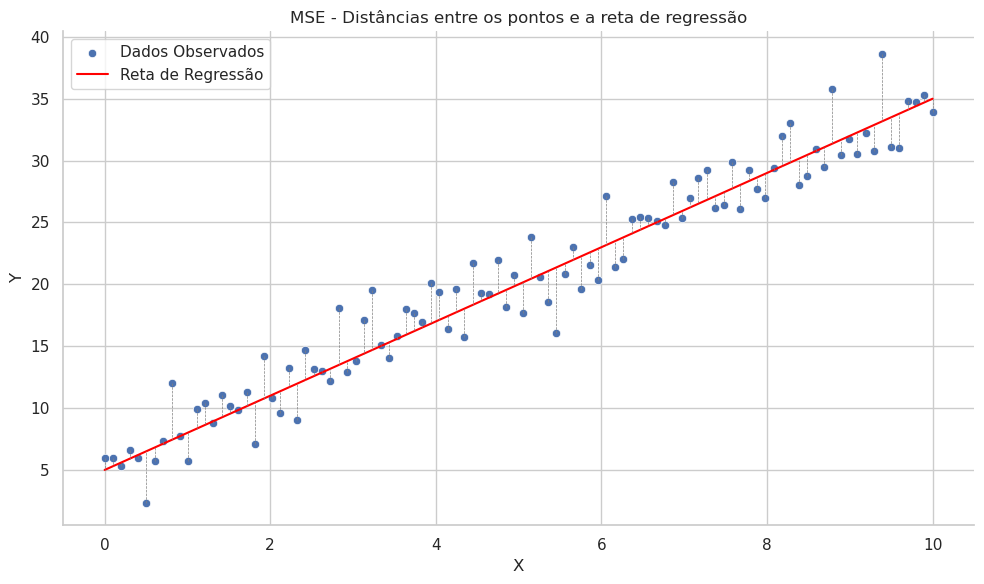

In [20]:
# Gráfico representando a MSE 
x = np.linspace(0, 10, 100)
y = 3 * x + 5 + np.random.normal(0, 2, size=x.shape)  # y = 3x + 5 + ruído gaussiano

plt.figure(figsize=(10, 6))
sns.scatterplot(x=x, y=y, marker='o', label='Dados Observados')
# Reta de regressão
y_pred = 3 * x + 5
plt.plot(x, y_pred, color='red', label='Reta de Regressão')

# Mostrar as distâncias (resíduos) entre os pontos e a reta de regressão
for i in range(len(x)):
    plt.plot([x[i], x[i]], [y[i], y_pred[i]], color='gray', linestyle='--', linewidth=0.5)

plt.xlabel('X')
plt.ylabel('Y')
plt.title('MSE - Distâncias entre os pontos e a reta de regressão')
plt.legend()
sns.despine()
plt.tight_layout()
plt.show()

Nesse exemplo do gráfico acima, temos uma reta de regressão e as linhas verticais representam o **erro** do modelo: a distância entre o valor previsto do valor real para aquele valor de x. É este erro que será elevado ao quadrado.

Agora conhecemos a principal Função de Custo utilizada na Regressão Linear, e sabemos que precisamos *minimizar* ou diminuir essa função ao máximo possível, uma dúvida pode ter surgido: *como, de fato, minimizar essa função* para treinar o modelo?

# Ideia de Derivada

Um conceito importantíssimo para aprender como os modelos de Aprendizado de Máquina "aprendem" é o conceito do Cálculo Diferencial de Derivada, e seu equivalente no Gradiente. Um curso mais aprofundado de Cálculo será necessário para aprender a extensão deste tópico vasto; aqui, focaremos apenas em uma abordagem intuitiva.

De modo geral, a derivada mede a **taxa de variação** de uma função em um ponto. Isto é, para uma função qualquer, a derivada da função em um ponto vai medir *o quanto a função está variando EXATAMENTE naquele ponto*. Pense em uma montanha, por exemplo: se você estar perto do topo da montanha, mas ainda não chegou na montanha, é provável que a derivada seja um número positivo alto, indicando que a montanha está ganhando altura rapidamente naquela região. Já no topo ou no vale de uma montanha, a derivada vai tender a zero, pois o terreno se assenta e para de variar com frequência, não ganhando e nem perdendo altura significativa.

Em um gráfico, a derivada pode ser entendida como a *inclinação da reta tangente*: se a derivada é positiva, a função cresce; se é negativa, a função diminui; e se é zero, chegamos a um ponto onde a função deixa de subir ou descer naquele instante. A intuição da derivada como inclinação da reta tangente ao ponto já é o suficiente para os propósitos do curso, mas, seguimos com uma descrição um pouco mais matemática:

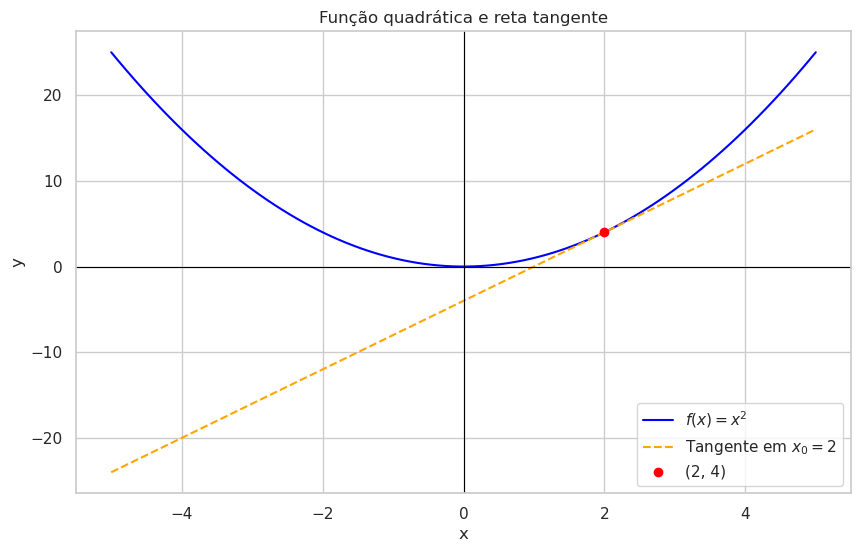

Derivada no ponto x0 = 4


In [21]:
# Fazer o gráfico de uma função x² com a reta tangente no ponto simbolizando a derivada no ponto
plt.figure(figsize=(10, 6))

# Função
x = np.linspace(-5, 5, 100)
y = x**2

# Escolher o ponto de tangência
x0 = 2
y0 = x0**2

# Derivada no ponto: inclinação da reta tangente
derivada = 2 * x0

# Equação da reta tangente
y_tangente = y0 + derivada * (x - x0)

# Gráficos
plt.plot(x, y, label=r'$f(x)=x^2$', color='blue')
plt.plot(x, y_tangente, label=rf'Tangente em $x_0={x0}$', 
         color='orange', linestyle='--')

# Destacar o ponto de tangência
plt.scatter(x0, y0, color='red', zorder=3, label=f'({x0}, {y0})')

plt.axhline(0, color='black', linewidth=0.8)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Função quadrática e reta tangente')
plt.grid(True)
plt.legend()
plt.show()
print("Derivada no ponto x0 =", derivada)

### A Derivada, intuição matemática

Não conseguimos descrever facilmente, matematicamente, a tangente a um ponto na função, mas podemos aproximá-la por meio de uma **reta secante**, da qual conseguimos calcular.  
A reta secante escolhida passará por dois pontos da curva da função. Para uma função $f(x)$, escolhendo um ponto $x$ e outro ponto $x + h$, formamos um triângulo retângulo:

- $\Delta x = h$ é o deslocamento horizontal;
- $\Delta y = f(x+h) - f(x)$ é o deslocamento vertical;
- $\frac{\Delta y}{\Delta x}$ é a inclinação da **secante**.

Assim, a inclinação média da reta secante entre os dois pontos é:

$$\frac{f(x + h) - f(x)}{h}$$

A inclinação dessa reta secante **não é a derivada** da função no ponto x, porém, a medida em que os valores de $h$ ficam menores e menores, o segundo ponto $(x +h)$ fica mais e mais próximo do primeiro ponto, fazendo a reta secante TENDER a reta tangente. A animação interativa abaixo mostra exatamente esse comportamento ocorrendo.

Assim, no *limite* (a medida que os valores de $h$ se aproximam de zero, mas nunca cheguem a valer zero), a reta secante converge cada vez mais para a tangente no ponto, e a inclinação dessa reta tangente é a derivada:

$$f'(x) = \lim_{h \to 0} \frac{f(x + h) - f(x)}{h}$$

Por exemplo, para a função $f(x) = x^2$, temos:

$$f'(x) = 2x$$

Que é a **função derivada** de $f(x)$.

In [22]:
# Animar a secante se aproximando da tangente em f(x) = x^2


funcao = lambda valor: valor ** 2
ponto_x = 2
x_funcao = np.linspace(0.5, 3.5, 300)
y_funcao = funcao(x_funcao)
hs_animacao = np.geomspace(2.0, 0.03, 70)
inclinacao_tangente = 2 * ponto_x

fig, eixo = plt.subplots(figsize=(10, 6))
eixo.plot(x_funcao, y_funcao, label='$f(x) = x^2$')
x_tangente = np.linspace(ponto_x - 1, ponto_x + 1, 100)
y_tangente = funcao(ponto_x) + inclinacao_tangente * (x_tangente - ponto_x)
eixo.plot(x_tangente, y_tangente, color='red', linestyle='--', alpha=0.6, label='Tangente no limite')

linha_secante, = eixo.plot([], [], color='orange', linestyle='--', label='Secante')
pontos_secante, = eixo.plot([], [], 'o', color='red', zorder=3)
linha_horizontal, = eixo.plot([], [], color='green', linewidth=2)
linha_vertical, = eixo.plot([], [], color='green', linewidth=2)
texto_delta_x = eixo.text(0, 0, '', color='green', ha='center')
texto_delta_y = eixo.text(0, 0, '', color='green')
texto_inclinacao = eixo.text(
    0.03,
    0.95,
    '',
    transform=eixo.transAxes,
    verticalalignment='top',
    bbox=dict(facecolor='white', alpha=0.85, edgecolor='none', pad=3)
)

eixo.set_xlim(0.5, 3.5)
eixo.set_ylim(-1, 13)
eixo.set_xlabel('x')
eixo.set_ylabel('f(x)')
eixo.set_title('A secante se transformando na tangente')
eixo.legend(loc='upper right')
sns.despine()


def atualizar_derivada(frame):
    passo = hs_animacao[frame]
    y_inicial = funcao(ponto_x)
    y_final = funcao(ponto_x + passo)
    inclinacao = (y_final - y_inicial) / passo
    x_secante = np.array([ponto_x - 0.2, ponto_x + passo + 0.2])
    y_secante = y_inicial + inclinacao * (x_secante - ponto_x)

    linha_secante.set_data(x_secante, y_secante)
    pontos_secante.set_data([ponto_x, ponto_x + passo], [y_inicial, y_final])
    linha_horizontal.set_data([ponto_x, ponto_x + passo], [y_inicial, y_inicial])
    linha_vertical.set_data([ponto_x + passo, ponto_x + passo], [y_inicial, y_final])
    texto_delta_x.set_position((ponto_x + passo / 2, y_inicial - 0.7))
    texto_delta_x.set_text(f'delta x = {passo:.2f}')
    texto_delta_y.set_position((ponto_x + passo + 0.04, (y_inicial + y_final) / 2))
    texto_delta_y.set_text(f'delta y = {y_final - y_inicial:.2f}')
    texto_inclinacao.set_text(f'h = {passo:.3f}   inclinacao = {inclinacao:.3f}')
    return (linha_secante, pontos_secante, linha_horizontal, linha_vertical,
            texto_delta_x, texto_delta_y, texto_inclinacao)


animacao_derivada = FuncAnimation(
    fig, atualizar_derivada, frames=len(hs_animacao), interval=80, blit=False
)
plt.close(fig)
HTML(animacao_derivada.to_jshtml())

O destaque aqui, que nos interessa para o aprendizado de máquina, é particularmente nas sitauções onde a **derivada é zero**, pois isso significa que, na região ao redor daquele ponto, a função não muda. Isso **pode** indicar um *mínimo global*, um ponto ande a função está assumindo o menor valor possível (ou um dos menores valores possíveis), que é exatamente a intuição por trás de "minimizar a função de custo".

# Noção Intuitiva do Método do Gradiente

A derivada nos mostra o quanto a função está variando em um ponto. Porém, para funções com múltiplas variáveis, como é o caso da nossa *função de custo* (que pode variar tanto em $a$ quanto em $b$, se lembra?), a derivada sozinha é insuficiente, pois essas funções não mais possuem apenas dois eixos, mas sim, 3 eixos ou mais, tornando a derivada convencional *incompleta*.
Pense, por exemplo, na função: $$z = x^2 + y^2$$
Essa é uma função que recebe *duas variáveis de entrada*, o que significa que precisa de um gráfico em *3 dimensões* para ser representada, com o eixo vertical $z$ sendo o responsável por mostrar o valor da função naquele ponto $(x, y)$.

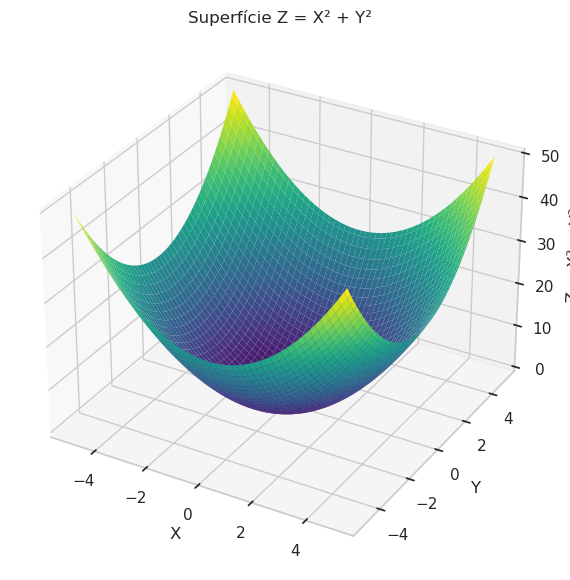

In [23]:
x = np.linspace(-5, 5, 100)
y = np.linspace(-5, 5, 100)

# Criar a grade 2D
X, Y = np.meshgrid(x, y)

# Calcular Z = x² + y²
Z = X**2 + Y**2

# Criar o gráfico 3D
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(X, Y, Z, cmap="viridis", edgecolor="none")

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z = X² + Y²")
ax.set_title("Superfície Z = X² + Y²")

plt.show()


Neste cenário, a derivada sozinha não bastaria, pois ela estaria medindo apenas a derivada **de um eixo específico** (como o eixo x, por exemplo). Para corretamente termos uma noção mais apropriada de *o quanto a função está variando naquele ponto*, precisamos avaliar uma espécie de derivada pra cada eixo de entrada da função. É aí que entram as **derivadas parciais**.

Uma derivada parcial é, essencialmente, a *derivada de uma função de duas ou mais variáveis em relação a uma das variáveis, mantendo as outras constantes*. Assim, por exemplo, a derivada parcial de $x^2 + y^2 = z$ *em relação a x* seria a derivada da função tratando $y$ como uma constante, que ficaria $2x$. Da mesma forma, a derivada parcial de $x^2 + y^2 = z$ *em relação a y* seria tratar $x$ como uma constante e resultaria em $2y$. A notação para uma função $f(x,y) = x^2 + y^2$:
$$\frac{\partial f}{\partial x} = 2x$$
$$\frac{\partial f}{\partial y} = 2y$$


O chamado **vetor gradiente** é a junção de todas as derivadas parciais. Com a função acima, nosso gradiente seria:

$$\nabla f = (2x, 2y)$$

Gradiente é um **vetor** que aponta para a direção onde a função estará *crescendo* na região daquele ponto $(x, y)$, ou seja, se nós seguirmos na direção em que o gradiente aponta, estaremos buscando achar um possível *valor máximo da função* (local ou global). Dessa forma, se nós fizermos *o caminho contrário do gradiente*, então, estaremos indo para a direção onde a função *diminui*, o que pode nos ajudar a encontrar o mínimo global da função, que é o que queremos na função de custo: como a função de custo *quantifica os erros*, minimizar os erros é encontrar os valores que tornam essa função a menor possível, tornando o modelo o mais preciso possível.

Assim sendo, o *método do Gradiente Descente* se resume em, basicamente:
1. Iniciar a Função de Custo com valores aleatórios para $a$ e $b$.
2. Extrair o gradiente da função, extraindo as derivadas parciais para $a$ e $b$.
3. Andar um pequeno passo (definido pelo parâmetro *learning rate* ou *taxa de aprendizado*) na direção **oposta** a do gradiente.
4. Repetir até o gradiente chegar a 0, próximo de zero, ou acabar o número de interações.

E este é o método mais comumente utilizado para treinar os modelos como a Regressão Linear, onde repetimos o algoritmo do *método do Gradiente Descente*, frequentemente versões simplificadas ou otimizadas desse algoritmo, até que a função se aproxime de um valor mínimo que representa os menores erros possíveis, e portanto, nos aproxima de valores $a$ e $b$ mais calibrados.

As regras do Cálculo diferencial nos dão o ferramental para entender em mais profundidade Derivadas, Gradientes e ideias como funções convexas, limites de convergência, e entre outras.

### Gradiente Descente, intuição matemática.

No método do Gradiente Descente, como queremos **diminuir** o erro, caminhamos na direção contrária ao gradiente. Em uma única dimensão, a regra é:

$$w_{novo} = w_{atual} - \alpha \frac{dJ}{dw}$$
Isto é, para descobrirmos qual o melhor valor para a variável que multiplica o $x$, a variável $w$ (ou $a$ nos exemplos anteriores, representando os pesos), precisamos utilizar o valor do peso anterior, e *subtrair* (andar na direção contrária) de um *pequeno passado no sentido do gradiente*.

Considere, por exemplo, a função $J(w) = w^2$. Se começarmos em $w = 2.5$, então:

$$J(2.5) = 6.25 \quad \text{e} \quad J'(2.5) = 5$$

Com $\alpha = 0.2$, o próximo passo será:

$$w_{novo} = 2.5 - 0.2 \times 5 = 1.5$$

O novo ponto está mais perto do mínimo, que acontece em $w = 0$. Repetindo a operação, caminhamos gradualmente para o menor custo. Se a taxa dee aprendizado (o passo) for muito grande, podemos passar pelo mínimo; se for muito pequena, o treinamento pode muito ser demorado.

In [24]:
# Animar os passos do gradiente descendente em J(w) = w^2
funcao_custo = lambda valor: valor ** 2
pontos = np.linspace(-3, 3, 300)
taxa_aprendizado = 0.2
ponto_atual = 2.5
historico = [ponto_atual]
custos_gradiente = [funcao_custo(ponto_atual)]

for _ in range(14):
    derivada = 2 * ponto_atual
    ponto_atual = ponto_atual - taxa_aprendizado * derivada
    historico.append(ponto_atual)
    custos_gradiente.append(funcao_custo(ponto_atual))

fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
eixos[0].plot(pontos, funcao_custo(pontos), label='$J(w) = w^2$')
trajetoria, = eixos[0].plot([], [], 'o--', color='red', label='Caminho do gradiente')
ponto_gradiente, = eixos[0].plot([], [], 'o', color='blue', markersize=9, zorder=3)
texto_passo = eixos[0].text(0.03, 0.92, '', transform=eixos[0].transAxes)
eixos[0].set_xlabel('Parametro w')
eixos[0].set_ylabel('Funcao de custo J(w)')
eixos[0].set_title('O ponto caminhando ate o minimo')
eixos[0].legend()

evolucao_custo, = eixos[1].plot([], [], 'o-', color='green')
eixos[1].set_xlim(0, len(custos_gradiente) - 1)
eixos[1].set_ylim(0, custos_gradiente[0] * 1.05)
eixos[1].set_xlabel('Passo')
eixos[1].set_ylabel('J(w)')
eixos[1].set_title('O custo diminuindo a cada atualizacao')
eixos[1].set_xticks(range(0, len(custos_gradiente), 2))

sns.despine()


def atualizar_gradiente(frame):
    pontos_atuais = np.array(historico[:frame + 1])
    custos_atuais = np.array(custos_gradiente[:frame + 1])
    trajetoria.set_data(pontos_atuais, custos_atuais)
    ponto_gradiente.set_data([historico[frame]], [custos_gradiente[frame]])
    evolucao_custo.set_data(range(frame + 1), custos_atuais)
    texto_passo.set_text(
        f'passo {frame}: w = {historico[frame]:.3f}\nJ(w) = {custos_gradiente[frame]:.4f}'
    )
    return trajetoria, ponto_gradiente, evolucao_custo, texto_passo


animacao_gradiente = FuncAnimation(
    fig, atualizar_gradiente, frames=len(historico), interval=350, blit=False
)
plt.close(fig)
HTML(animacao_gradiente.to_jshtml())

# Juntando tudo - Regressão Linear do Zero (Exemplo)

Vamos implementar o que aprendemos até agora criando um modelo de regressão linear do zero.

Parametros aprendidos: b0=4.6931, b1=3.0190
Erro final (MSE): 4.0912


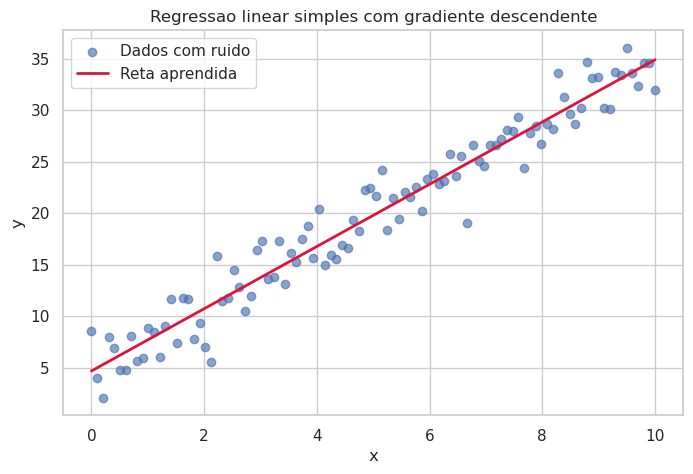

In [25]:
# Regressao linear simples do zero usando as classes de utils.py
#
# O modelo que queremos aprender e:
#     y_pred = b0 + b1 * x
#
# b0 e o intercepto e b1 e a inclinacao da reta.

# 1) Criar dados de exemplo
x = np.linspace(0, 10, 100).reshape(-1, 1)
y = 3 * x + 5 + np.random.normal(0, 2, size=x.shape)

# 2) Comecar com uma reta ruim: b0 = 0 e b1 = 0
model = SingleLinearRegression(b0=0, b1=0)
mse = MSE()

# 3) Treinar com gradiente descendente
gradient_descent = GradientDescent()
model = gradient_descent.fit(
    model,
    x,
    y,
    learning_rate=0.01,
    epochs=1000,
)

predictions = model.predict(x)
print(f'Parametros aprendidos: b0={model.b0:.4f}, b1={model.b1:.4f}')
print(f'Erro final (MSE): {mse.calculate(y, predictions):.4f}')

# 4) Visualizar os dados e a reta aprendida
plt.figure(figsize=(8, 5))
plt.scatter(x, y, alpha=0.65, label='Dados com ruido')
plt.plot(x, predictions, color='crimson', linewidth=2, label='Reta aprendida')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Regressao linear simples com gradiente descendente')
plt.legend()
plt.show()


# Regressão Linear no dataset de Uso de Combustível
Finalmente, após entendermos toda o tratamento de dados atẽ então e aprendermos como funciona o modelo de Regressão Linear, iremos treinar um modelo de regressão linear *múltipla* com o auxílio da biblioteca *Scikit-Learn*, que já faz o treinamento e teste do modelo de forma muito mais rápida e eficiente.
Iremos dividir os dados entre diferentes porções para as distribuições de `x`e de `y`. Iremos criar um `x_train`, `x_test`, `y_train`, `y_test`, para podemos testar o modelo em um conjunto diferente dos dados em que ele foi treinado, para garantir que o modelo está generalizando bem para dados que ele nunca viu antes.

In [6]:
df = pd.read_csv(caminho_dataset("FuelConsumptionCo2.csv"))
x = df[["ENGINESIZE", "CYLINDERS", "FUELCONSUMPTION_CITY", "FUELCONSUMPTION_HWY", "FUELCONSUMPTION_COMB"]]
y = df["CO2EMISSIONS"]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [27]:
model = LinearRegression()
model.fit(x_train, y_train);
y_pred = model.predict(x_test)
mse = mean_squared_error(y_test, y_pred);
mae = mean_absolute_error(y_test, y_pred);
r2 = r2_score(y_test, y_pred);

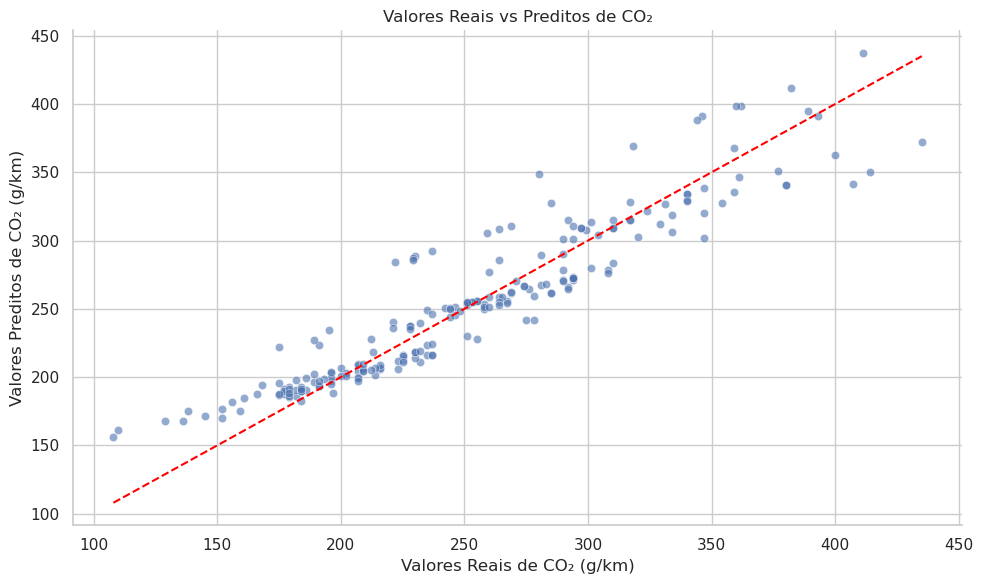

In [28]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--')
plt.xlabel('Valores Reais de CO₂ (g/km)')
plt.ylabel('Valores Preditos de CO₂ (g/km)')
plt.title('Valores Reais vs Preditos de CO₂')
sns.despine()
plt.tight_layout()
plt.show()

In [29]:
print(f'RMSE: {np.sqrt(mse).round(2)} g/km')
print(f'MAE: {mae:.2f} g/km')
print(f'R² do modelo {r2:.3f}')

RMSE: 22.61 g/km
MAE: 16.69 g/km
R² do modelo 0.876


## Avaliação final do modelo de emissão de CO₂

### O que significam as métricas padrão?
Cada modelo de aprendizado de máquina possui seus próprios conjuntos de métricas, para modelos de regressão como o que treinamos, os mais comuns são os seguintes.

- **R² (coeficiente de determinação):** indica a proporção da variação dos valores reais que é explicada pelo modelo. Seu valor varia, em geral, de 0 a 1: quanto mais próximo de 1, melhor. Um valor negativo indica que o modelo é pior do que simplesmente prever a média dos dados. 
$$
\begin{align*}
R^2 &= \frac{\text{SQ}_{\text{res}}}{\text{SQT}} \\[1ex]
\text{SQ}_{\text{res}} &= \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 \\[1ex]
\text{SQT} &= \sum_{i=1}^{n} (y_i - \bar{y})^2
\end{align*}
$$


- **MAE (Mean Absolute Error / Erro Absoluto Médio):** calcula a média das diferenças absolutas entre os valores reais e previstos. É uma medida fácil de interpretar porque mantém a mesma unidade da variável prevista, neste caso, **g/km de CO₂**.
$$
\begin{align*}
\text{MAE} &= \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i| \\[1.5ex]
\end{align*}
$$

- **RMSE (Root Mean Squared Error / Raiz do Erro Quadrático Médio):** calcula a raiz da média dos erros ao quadrado. Também é expresso em **g/km**, mas penaliza mais fortemente erros grandes do que o MAE.

$$
\begin{align*}
\text{RMSE} &= \sqrt{\frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2}
\end{align*}
$$

### Resultado no conjunto de teste

Com 20% dos dados reservados para teste, obtivemos:

- **R² = 0,876:** o modelo explica aproximadamente **87,6% da variação** nas emissões de CO₂ do conjunto de teste.
- **MAE = 16,69 g/km:** em média, as previsões ficaram cerca de **16,69 g/km** distantes dos valores reais.
- **RMSE = 22,61 g/km:** considerando a penalização de erros maiores, o erro típico ficou em torno de **22,61 g/km**.


### Avaliação final

O resultado do nosso modelo é **bom**: o R² é alto e o MAE é relativamente pequeno em comparação com a variação das emissões no dataset. Como o RMSE é maior que o MAE, existem algumas previsões com erros mais elevados que aumentam a penalização dos desvios grandes.
Esse resultado não significa que o modelo seja perfeito. Próximas etapas de um processo normal de Ciência de Dados seria analisar os resíduos (erros do modelo, se há um padrão nos erros), analisar quais variáveis mais contribuiram para a performance final do modelo, etc, investigar possíveis outliers e validar o modelo com outros recortes dos dados. Mas, para o que pretendíamos abrangir nesta aula, nós conseguimos criar um modelo com acurácia relativamente alta capaz de prever o consumo de CO² com base em dados do veículo.